# дз 1: рекомендации товаров
халилов арслан шамильевич

данные — [amazon video games 2014](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/links_local.html). рекомендую игры, консоли и аксессуары. взаимодействие — отзыв; релевантность — будущая оценка 4–5. сравниваю пять моделей по общей выдаче top-10.

## запуск
python 3.12, из корня репозитория:
```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r hw1/requirements.txt
python hw1/run_notebook.py
```
скрипт выполняет ноутбук и сохраняет ячейки. данные скачиваются в `.cache/recsys/`, проверяются по SHA-256 и не попадают в git. другой путь: `RECSYS_DATA_DIR`. можно открыть ноутбук с тем же окружением и выполнить все ячейки. проверки: `cd hw1 && python -m unittest -v test_correctness`.

In [1]:
from pathlib import Path
import os, sys, json, platform, random
if Path('hw1').is_dir():
    os.chdir('hw1')
import numpy as np
import pandas as pd
import scipy, torch, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from data_utils import download_data, prepare_data, matrices, build_features, TRAIN_END, VALID_END
from evaluation import relevance
from experiment import SEARCH, tune, final_evaluation
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
thread_limit = threadpool_limits(limits=2)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)
Path('results').mkdir(exist_ok=True)
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scipy': scipy.__version__, 'torch': torch.__version__, 'matplotlib': matplotlib.__version__,
            'platform': platform.platform(), 'seed': SEED, 'threads': 2}
Path('results/environment.json').write_text(json.dumps(versions, indent=2))
display(pd.Series(versions, name='environment'))

python                             3.12.14
numpy                                2.5.4
pandas                               3.1.0
scipy                               1.18.1
torch                               2.14.1
matplotlib                          3.11.2
platform      macOS-26.6.2-arm64-arm-64bit
seed                                    42
threads                                  2
Name: environment, dtype: object

## данные
исходный CSV содержит 1 324 753 отзыва. поля: `reviewerID` — пользователь, `asin` — товар, `rating` — оценка 1–5, `timestamp` — дата отзыва в unix seconds. второй файл содержит названия, категории и бренды товаров.

удаляю строки с пропусками и некорректными оценками. для повторной пары оставляю первый отзыв; при равной дате сортирую по ID и оценке. беру 3 000 самых популярных товаров до 2013-01-01 и пользователей минимум с тремя отзывами об этих товарах до той же даты. при равной популярности сортирую ASIN. товары без оставшихся пользователей удаляю. отбор не использует будущую активность; готовый 5-core по этой причине не беру.

ограничение каталога снижает расход памяти EASE. выборка смещена к популярным товарам с историей. итоговые объёмы, пропуски и дубликаты — ниже.

In [2]:
cache = download_data()
data = prepare_data(cache)
audit = data['audit']
Path('results/data_audit.json').write_text(json.dumps(audit, indent=2, default=int))
display(pd.Series({k: v for k, v in audit.items() if k != 'missing'}, name='value').to_frame())
display(pd.Series(audit['missing'], name='missing_rows').to_frame())
print('диапазон дат:', pd.to_datetime(audit['first_timestamp'], unit='s', utc=True), '—',
      pd.to_datetime(audit['last_timestamp'], unit='s', utc=True))

,value
raw_rows,1.324753e+06
raw_users,8.267670e+05
raw_items,5.021000e+04
exact_duplicates,0.000000e+00
repeated_user_item,0.000000e+00
clean_rows,1.324753e+06
selected_rows,1.351790e+05
users,2.374500e+04
items,2.999000e+03
train_rows,1.279830e+05


,missing_rows
reviewerID,0
asin,0
rating,0
timestamp,0


диапазон дат: 1999-10-14 00:00:00+00:00 — 2014-07-16 00:00:00+00:00


,reviews_per_user,reviews_per_item
count,23745.000000,2999.000000
mean,5.692946,45.074692
std,7.182581,50.322838
min,3.000000,1.000000
50%,4.000000,30.000000
90%,10.000000,92.000000
99%,30.000000,270.000000
max,443.000000,544.000000


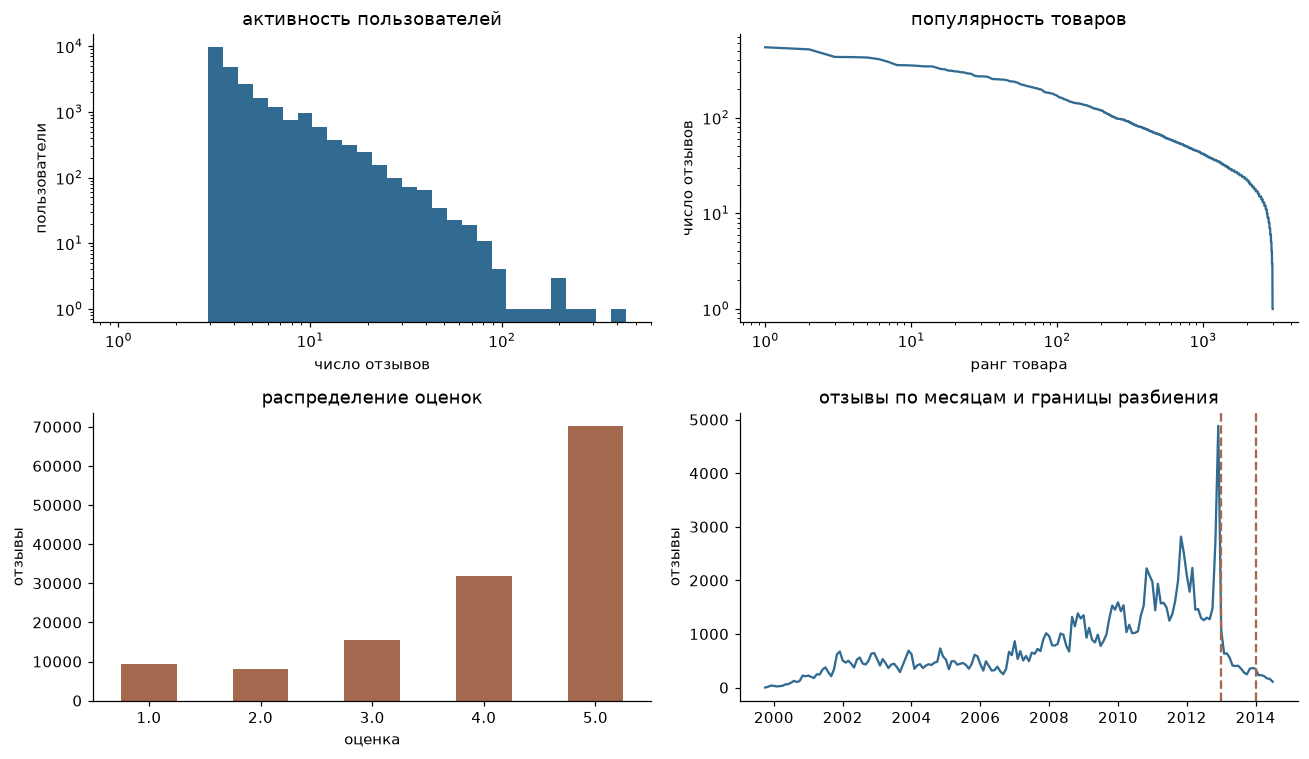

положительных отзывов (4–5): 75.46%
на 10% самых популярных товаров приходится 36.41% отзывов.


In [3]:
selected, train = data['selected'], data['train']
activity = selected.groupby('user').size()
popularity = selected.groupby('item').size()
display(pd.DataFrame({'reviews_per_user': activity.describe(percentiles=[.5, .9, .99]),
                      'reviews_per_item': popularity.describe(percentiles=[.5, .9, .99])}))
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].hist(activity, bins=np.geomspace(1, activity.max()+1, 35), color='#326b91')
ax[0, 0].set(xscale='log', yscale='log', title='активность пользователей', xlabel='число отзывов', ylabel='пользователи')
ax[0, 1].plot(np.arange(1, len(popularity)+1), popularity.sort_values(ascending=False), color='#326b91')
ax[0, 1].set(xscale='log', yscale='log', title='популярность товаров', xlabel='ранг товара', ylabel='число отзывов')
selected.rating.value_counts().sort_index().plot.bar(ax=ax[1, 0], color='#a5694f', rot=0)
ax[1, 0].set(title='распределение оценок', xlabel='оценка', ylabel='отзывы')
monthly = selected.assign(month=pd.to_datetime(selected.timestamp, unit='s').dt.to_period('M')).groupby('month').size()
ax[1, 1].plot(monthly.index.to_timestamp(), monthly.values, color='#326b91')
for date in ['2013-01-01', '2014-01-01']:
    ax[1, 1].axvline(pd.Timestamp(date), color='#a5694f', linestyle='--')
ax[1, 1].set(title='отзывы по месяцам и границы разбиения', ylabel='отзывы')
fig.tight_layout(); fig.savefig('results/eda.png', dpi=150); plt.show()
print(f'положительных отзывов (4–5): {selected.rating.ge(4).mean():.2%}')
print(f'на 10% самых популярных товаров приходится {popularity.nlargest(max(1, len(popularity)//10)).sum()/len(selected):.2%} отзывов.')

## метапризнаки
карточки товаров нужны для EDA. их исторических версий нет, поэтому цены, `salesRank`, связи товаров, названия и категории в FM не использую.

к ID добавляю пять признаков из прошлой истории: число отзывов пользователя, дни с его последнего отзыва, число отзывов товара, дни с первого отзыва о товаре и долю отзывов за последние 180 дней. временной источник — `timestamp`. возраст товара здесь отсчитывается от первого наблюдаемого отзыва, не от выпуска.

все признаки доступны в момент выдачи. интервалы заданы заранее; каждый интервал кодируется отдельным one-hot признаком. FM может учить, например, предпочтения пользователя по давности товара. вклад признаков проверяю сравнением с той же FM только на ID.

,field,missing_items,unique_nonempty
0,title,2880,118
1,category,0,212
2,brand,2946,20


,title,category
0,,Video Games / PlayStation 3 / Accessories / Controllers / Microphones
1,,Video Games / More Systems / Nintendo 64 / Hardware / Accessories
2,,Video Games / Xbox 360 / Accessories
3,"2 Pack - Gator Crunch Wii Gamecube 6FT Extension Cable / Cord (Lifetime Warranty, Bulk packaging)",Video Games / Wii
4,,Video Games / PC / Games
5,,Video Games / PC / Games
6,,Video Games / PC / Games
7,,Video Games / Kids & Family


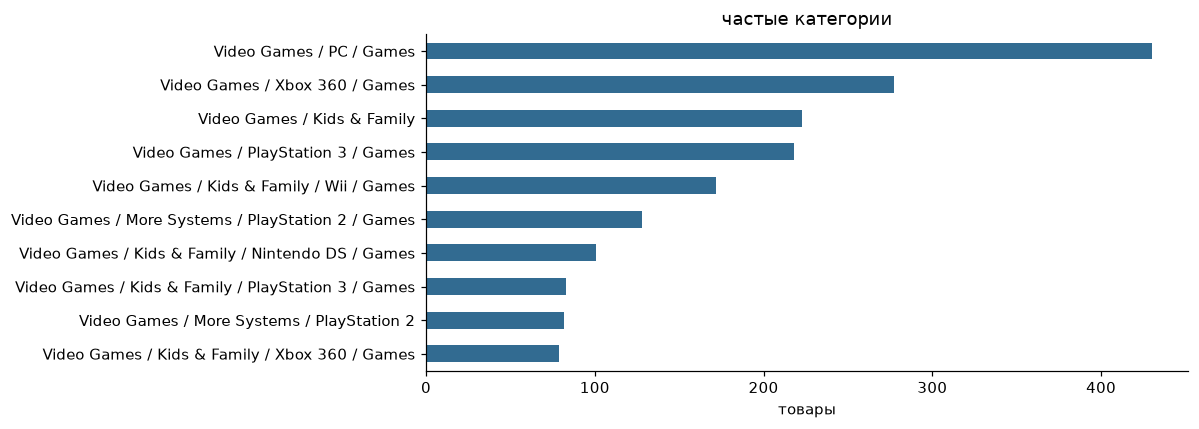

,feature,min,median,max,bins
0,user_review_count,3.0,4.00,439.0,"[5, 10, 20, 50, 100]"
1,user_days_since_last_review,1.0,637.00,4774.0,"[30, 90, 180, 365, 730]"
2,item_review_count,1.0,28.00,539.0,"[10, 30, 100, 300, 1000]"
3,item_days_since_first_review,20.0,1588.00,4828.0,"[30, 180, 365, 730, 1825]"
4,item_recent_review_share,0.0,0.04,1.0,"[0.05, 0.2, 0.5, 0.8]"


размеры матриц активных признаков: (23745, 3) (2999, 4)


In [4]:
metadata = data['metadata']
display(pd.DataFrame({'field': ['title', 'category', 'brand'],
                      'missing_items': [(metadata[c] == '').sum() for c in ['title', 'category', 'brand']],
                      'unique_nonempty': [metadata.loc[metadata[c] != '', c].nunique() for c in ['title', 'category', 'brand']]}))
display(metadata[['title', 'category']].head(8))
fig, ax = plt.subplots(figsize=(11, 4))
metadata.category.replace('', 'нет категории').value_counts().head(10).sort_values().plot.barh(ax=ax, color='#326b91')
ax.set(xlabel='товары', ylabel='', title='частые категории')
fig.tight_layout(); fig.savefig('results/categories.png', dpi=150); plt.show()
uf, itf, feature_stats = build_features(train, data['shape'], TRAIN_END)
display(feature_stats)
print('размеры матриц активных признаков:', uf.shape, itf.shape)

## оценка
train — до 2013-01-01 UTC; validation — 2013 год; test — с 2014-01-01 до конца данных. после подбора переобучаю модели на train + validation. выдача строится на начало периода и внутри него не обновляется.

кандидаты — весь выбранный каталог, без сэмплирования при оценке. исключаю все ранее оценённые товары, включая оценки 1–3. каталог и пользовательская когорта фиксируются на train; новые пользователи и товары исключаются. объём отсева — в таблице. метрики считаю по пользователям хотя бы с одним релевантным товаром в периоде. внутри каждого этапа пользователи и кандидаты одинаковы у всех моделей. равные score разрешаются по возрастанию ASIN.

основную метрику выбираю до подбора: **NDCG@10**. она учитывает позицию полезного товара. **Recall@10** показывает долю найденных релевантных товаров:
$$\mathrm{NDCG@10}_u=\frac{\sum_{j=1}^{10}\mathbf1[L_{uj}\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)},\qquad
\mathrm{Recall@10}_u=\frac{|L_u\cap R_u|}{|R_u|}.$$
$R_u$ — будущие товары с оценкой 4–5, $L_u$ — выдача. усредняю по пользователям. дополнительно показываю HitRate@10 — долю пользователей с попаданием, Coverage@10 — долю каталога в выдачах. отсутствие отзыва не означает отсутствие интереса.

In [5]:
split_rows = []
for label, key in [('train', 'train'), ('validation', 'valid'), ('test', 'test')]:
    part = data[key]
    positives = part[part.rating >= 4]
    split_rows.append({'split': label, 'interactions': len(part), 'active_users': part.user.nunique(),
                       'active_items': part.item.nunique(), 'relevant_interactions': len(positives),
                       'users_with_relevance': positives.user.nunique(),
                       'cohort_users_without_relevance': data['shape'][0] - positives.user.nunique()})
split_table = pd.DataFrame(split_rows)
display(split_table); display(data['exclusions'])
split_table.to_csv('results/splits.csv', index=False)
data['exclusions'].to_csv('results/exclusions.csv', index=False)
ratings, timestamps, positive, seen = matrices(train, data['shape'])
assert seen.shape == positive.shape == data['shape']
assert train.timestamp.max() < TRAIN_END
print('каталог для каждой модели:', data['shape'][1], 'товаров до исключения известных.')

,split,interactions,active_users,active_items,relevant_interactions,users_with_relevance,cohort_users_without_relevance
0,train,127983,23745,2999,96467,22914,831
1,validation,5720,2713,1534,4393,2218,21527
2,test,1476,852,784,1143,691,23054


,split,all_reviews,outside_user_cohort,outside_catalog,excluded_union,retained
0,validation,362860,346208,224390,357140,5720
1,test,222009,214995,166176,220533,1476


каталог для каждой модели: 2999 товаров до исключения известных.


## модели
$X_{ui}=1$ для обучающих оценок 4–5; $\Omega$ — все наблюдаемые оценки.

**ItemKNN.** cosine между товарами с поправкой на число общих пользователей $n_{ij}$:
$$s_{ij}=\frac{X_{:i}^\top X_{:j}}{\|X_{:i}\|\|X_{:j}\|}\frac{n_{ij}}{n_{ij}+\beta},\quad s_{ii}=0,\qquad
\hat r_{ui}=\sum_{j\in N_k(i)}X_{uj}s_{ji}.$$
для каждого товара сохраняю $k$ соседей. поправка снижает вес редких совпадений.

**iALS.** $p_{ui}=\mathbf1[(u,i)\in\Omega,r_{ui}\ge4]$, $c_{ui}=1+\alpha\mathbf1[(u,i)\in\Omega]$:
$$\min_{A,B}\sum_{u,i}c_{ui}(p_{ui}-a_u^\top b_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2).$$
низкая оценка и отсутствие отзыва имеют нулевой таргет, но разный confidence. попеременно решаю системы для пользователей и товаров:
$$a_u=(B^\top B+\alpha\sum_{i\in\Omega_u}b_ib_i^\top+\lambda I)^{-1}(1+\alpha)\sum_{i\in\Omega_u}p_{ui}b_i.$$
в коде использую разложение Холецкого. score — $a_u^\top b_i$.

**EASE.**
$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\quad\mathrm{diag}(W)=0.$$
для $P=(X^\top X+\lambda I)^{-1}$ решение: $W_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$. score — $(XW)_{ui}$. нулевая диагональ исключает копирование входа.

**FM.** для one-hot признаков ID и метаданных:
$$f(x)=w_0+\sum_jw_jx_j+\frac12\sum_{q=1}^{d}\left[\left(\sum_jv_{jq}x_j\right)^2-\sum_jv_{jq}^2x_j^2\right].$$
обучаю с BCE: оценки 4–5 положительные, 1–3 отрицательные. на каждый положительный отзыв добавляю три случайных неизвестных товара; пересэмплирую их каждую эпоху. исключаю только обучающие взаимодействия, не подглядывая в holdout. использую Adam с `weight_decay`; формула FM, обучение и выдача написаны самостоятельно. полный каталог считаю через точное разложение score на пользовательскую, товарную и перекрёстную части.

**custom ALS.** заменяю бинарный таргет на знаковую оценку с затуханием:
$$q_{ui}=\frac{r_{ui}-3}{2}\left(\frac12+\frac12\,2^{-(T-t_{ui})/(86400\tau)}\right),\quad (u,i)\in\Omega;\qquad q_{ui}=0\text{ иначе}.$$
$T$ — момент выдачи, $\tau$ — полупериод в днях. оценки 1–2 дают отрицательный сигнал, 3 — нулевой, 4–5 — положительный разной силы. старые отзывы сохраняют хотя бы половину амплитуды.

в потере iALS заменяю $p$ на $q$, меняя правую часть нормальных уравнений. confidence и все параметры оптимизации сохраняю от выбранного iALS. подбираю только $\tau\in\{180,730\}$. тестовая релевантность у моделей одна: оценка 4–5.

In [6]:
from test_correctness import CorrectnessTests
import unittest
suite = unittest.defaultTestLoader.loadTestsFromTestCase(CorrectnessTests)
check = unittest.TextTestRunner(verbosity=2).run(suite)
assert check.wasSuccessful()

test_als_reproducible (test_correctness.CorrectnessTests.test_als_reproducible) ... 

ok


test_als_step_matches_dense_weighted_least_squares (test_correctness.CorrectnessTests.test_als_step_matches_dense_weighted_least_squares) ... 

ok


test_custom_target_changes_rhs_not_confidence (test_correctness.CorrectnessTests.test_custom_target_changes_rhs_not_confidence) ... 

...

test_metrics_known_ranking (test_correctness.CorrectnessTests.test_metrics_known_ranking) ... 

ok


test_seen_filter_and_stable_ties (test_correctness.CorrectnessTests.test_seen_filter_and_stable_ties) ... 

ok


----------------------------------------------------------------------
Ran 8 tests in 0.008s

OK


## подбор
всего 17 конфигураций, выбор по validation NDCG@10:

| модель | сетка |
|---|---|
| ItemKNN | соседи: 50, 150; shrinkage: 10, 50 |
| iALS | факторы: 32, 64; λ: 10, 50; α = 20; 12 итераций |
| EASE | λ: 50, 200, 1000 |
| FM | эпохи: 8, 16; lr: 0.003, 0.01; 32 фактора; 3 негатива; weight decay = 1e-5 |
| custom ALS | выбранный iALS; τ: 180, 730 дней |

при равенстве метрики беру первую конфигурацию. настройки сохраняю до расчёта test. FM без метапризнаков получает настройки основной FM без отдельного подбора.

In [7]:
display(pd.DataFrame([{'model': name, 'configuration': json.dumps(config, sort_keys=True)}
                      for name, configs in SEARCH.items() for config in configs]))
validation, chosen = tune(data)
display(validation.sort_values(['model', 'NDCG@10'], ascending=[True, False]))
display(pd.DataFrame([{'model': name, 'selected_parameters': json.dumps(config, sort_keys=True)}
                      for name, config in chosen.items()]))

,model,configuration
0,ItemKNN,"{""neighbors"": 50, ""shrinkage"": 10}"
1,ItemKNN,"{""neighbors"": 50, ""shrinkage"": 50}"
2,ItemKNN,"{""neighbors"": 150, ""shrinkage"": 10}"
3,ItemKNN,"{""neighbors"": 150, ""shrinkage"": 50}"
4,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 12, ""regularization"": 10.0, ""seed"": 42}"
5,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 12, ""regularization"": 50.0, ""seed"": 42}"
6,iALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 12, ""regularization"": 10.0, ""seed"": 42}"
7,iALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 12, ""regularization"": 50.0, ""seed"": 42}"
8,EASE,"{""regularization"": 50.0}"
9,EASE,"{""regularization"": 200.0}"


,model,parameters,fit_seconds,NDCG@10,Recall@10,HitRate@10,Coverage@10,evaluation_users
15,CustomALS,"{""alpha"": 20.0, ""factors"": 64, ""half_life_days"": 180.0, ""iterations"": 12, ""regularization"": 50.0, ""seed"": 42}",8.137067,0.051356,0.077497,0.125789,0.252084,2218
16,CustomALS,"{""alpha"": 20.0, ""factors"": 64, ""half_life_days"": 730.0, ""iterations"": 12, ""regularization"": 50.0, ""seed"": 42}",8.226031,0.047728,0.069071,0.116321,0.259086,2218
8,EASE,"{""regularization"": 50.0}",0.133462,0.047480,0.072042,0.125789,0.639547,2218
9,EASE,"{""regularization"": 200.0}",0.122581,0.046555,0.073265,0.126240,0.562187,2218
10,EASE,"{""regularization"": 1000.0}",0.136146,0.042527,0.067033,0.117674,0.510504,2218
14,FM,"{""batch_size"": 4096, ""epochs"": 16, ""factors"": 32, ""learning_rate"": 0.01, ""negatives"": 3, ""seed"": 42, ""weight_decay"": 1e-05}",4.483111,0.021863,0.034021,0.065825,0.243414,2218
11,FM,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 32, ""learning_rate"": 0.003, ""negatives"": 3, ""seed"": 42, ""weight_decay"": 1e-05}",2.226516,0.018832,0.032577,0.059513,0.159386,2218
12,FM,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 32, ""learning_rate"": 0.01, ""negatives"": 3, ""seed"": 42, ""weight_decay"": 1e-05}",2.412332,0.018020,0.032026,0.057710,0.161387,2218
13,FM,"{""batch_size"": 4096, ""epochs"": 16, ""factors"": 32, ""learning_rate"": 0.003, ""negatives"": 3, ""seed"": 42, ""weight_decay"": 1e-05}",4.873397,0.017272,0.027889,0.050496,0.239080,2218
2,ItemKNN,"{""neighbors"": 150, ""shrinkage"": 10}",0.170560,0.041463,0.066057,0.111362,0.696566,2218


,model,selected_parameters
0,ItemKNN,"{""neighbors"": 150, ""shrinkage"": 10}"
1,iALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 12, ""regularization"": 50.0, ""seed"": 42}"
2,EASE,"{""regularization"": 50.0}"
3,FM,"{""batch_size"": 4096, ""epochs"": 16, ""factors"": 32, ""learning_rate"": 0.01, ""negatives"": 3, ""seed"": 42, ""weight_decay"": 1e-05}"
4,CustomALS,"{""alpha"": 20.0, ""factors"": 64, ""half_life_days"": 180.0, ""iterations"": 12, ""regularization"": 50.0, ""seed"": 42}"


## test
выбранные модели обучаются заново на train + validation. признаки FM и давность отзывов пересчитываются к 2014-01-01. каталог и когорта сохраняются.

,model,NDCG@10,Recall@10,HitRate@10,Coverage@10,evaluation_users,fit_seconds,evaluation_seconds,parameters
4,CustomALS,0.058373,0.095959,0.137482,0.208403,691,8.134537,0.111038,"{""alpha"": 20.0, ""factors"": 64, ""half_life_days"": 180.0, ""iterations"": 12, ""regularization"": 50.0, ""seed"": 42}"
1,iALS,0.055726,0.100070,0.134588,0.268423,691,8.038657,0.109798,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 12, ""regularization"": 50.0, ""seed"": 42}"
2,EASE,0.054329,0.090107,0.127352,0.418806,691,0.127183,0.183604,"{""regularization"": 50.0}"
0,ItemKNN,0.048100,0.083968,0.120116,0.424141,691,0.196094,0.069663,"{""neighbors"": 150, ""shrinkage"": 10}"
3,FM,0.028792,0.048668,0.072359,0.163054,691,4.704185,0.110666,"{""batch_size"": 4096, ""epochs"": 16, ""factors"": 32, ""learning_rate"": 0.01, ""negatives"": 3, ""seed"": 42, ""weight_decay"": 1e-05}"


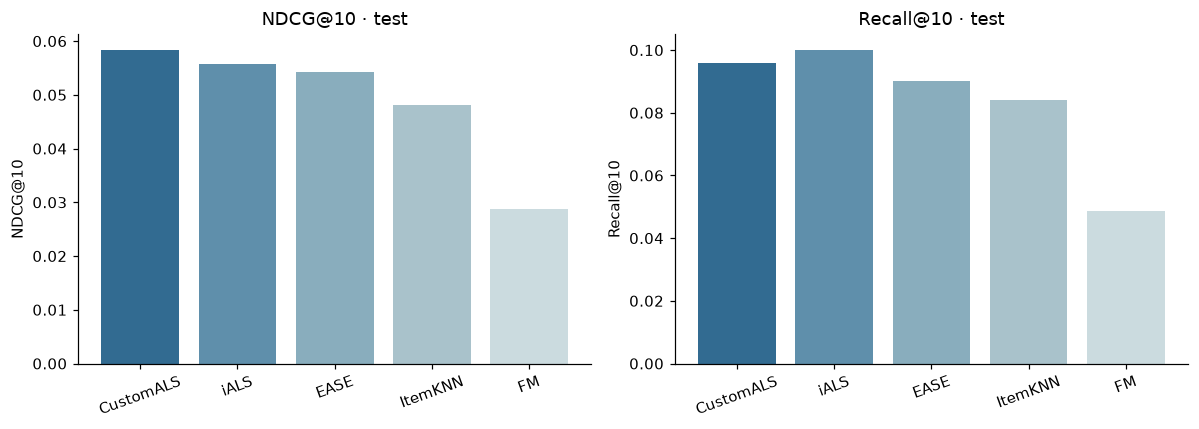

In [8]:
results, comparisons, loss_curves = final_evaluation(data, chosen)
main = results[results.model != 'FM_ID_only'].sort_values('NDCG@10', ascending=False)
display(main[['model', 'NDCG@10', 'Recall@10', 'HitRate@10', 'Coverage@10',
              'evaluation_users', 'fit_seconds', 'evaluation_seconds', 'parameters']])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    ax.bar(main.model, main[metric], color=['#326b91', '#5f8fab', '#89adbd', '#a9c2cb', '#cbdbdf'])
    ax.set(title=metric + ' · test', ylabel=metric)
    ax.tick_params(axis='x', rotation=20)
fig.tight_layout(); fig.savefig('results/comparison.png', dpi=150); plt.show()

## абляции
для разницы NDCG считаю парный bootstrap по тем же пользователям: 2 000 повторов, seed = 42, 95% процентильный интервал. он не учитывает другие временные разбиения и случайность обучения.

,model,NDCG@10,Recall@10,Coverage@10
1,iALS,0.055726,0.100070,0.268423
3,FM,0.028792,0.048668,0.163054
4,CustomALS,0.058373,0.095959,0.208403
5,FM_ID_only,0.051547,0.084675,0.089697


,mean_difference,ci_low,ci_high,users
FM_minus_ID_only,-0.022755,-0.036013,-0.010491,691.0
CustomALS_minus_iALS,0.002647,-0.006339,0.011778,691.0


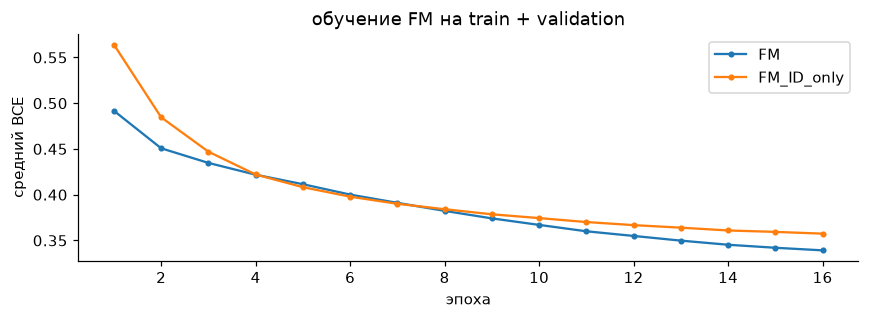

In [9]:
display(results[results.model.isin(['FM', 'FM_ID_only', 'iALS', 'CustomALS'])]
        [['model', 'NDCG@10', 'Recall@10', 'Coverage@10']])
display(pd.DataFrame(comparisons).T)
fig, ax = plt.subplots(figsize=(8, 3))
for name, values in loss_curves.items():
    ax.plot(np.arange(1, len(values)+1), values, marker='.', label=name)
ax.set(xlabel='эпоха', ylabel='средний BCE', title='обучение FM на train + validation')
ax.legend(); fig.tight_layout(); fig.savefig('results/fm_loss.png', dpi=150); plt.show()

## выводы

In [10]:
best = main.iloc[0]
base = results.set_index('model')
fm_delta = comparisons['FM_minus_ID_only']
als_delta = comparisons['CustomALS_minus_iALS']
conclusion = f"""по NDCG@10 первым оказался **{best['model']} — {best['NDCG@10']:.5f}**. лучший Recall@10 у **{main.loc[main['Recall@10'].idxmax(), 'model']} — {main['Recall@10'].max():.5f}**. на validation лидировал EASE с λ = 50; у iALS выбраны 64 фактора и λ = 50, у custom ALS — τ = 180 дней.

у custom ALS разница с iALS по NDCG равна {als_delta['mean_difference']:+.5f}, 95% интервал [{als_delta['ci_low']:+.5f}; {als_delta['ci_high']:+.5f}]. он включает ноль: устойчивое преимущество не установлено. шкала оценок и затухание изменены вместе, их отдельный вклад не измерялся.

метапризнаки ухудшили FM: {base.loc['FM', 'NDCG@10']:.5f} против {base.loc['FM_ID_only', 'NDCG@10']:.5f} без них. разница {fm_delta['mean_difference']:+.5f}, интервал [{fm_delta['ci_low']:+.5f}; {fm_delta['ci_high']:+.5f}]. меньший обучающий BCE не дал лучшего ранжирования. это результат для признаков активности и времени при общей настройке; категории и тексты здесь не проверялись.

в выборке {audit['selected_rows']} взаимодействий, {audit['users']} пользователей и {audit['items']} товаров. на test метрики считаются по {int(best['evaluation_users'])} пользователям. каталог ограничен прошлой популярностью, большая часть будущих отзывов исключена. проверено одно разбиение, один seed и небольшая сетка; выводы не описывают новые товары или весь amazon.
"""
display(Markdown(conclusion))
Path('results/conclusions.txt').write_text(conclusion)

по NDCG@10 первым оказался **CustomALS — 0.05837**. лучший Recall@10 у **iALS — 0.10007**. на validation лидировал EASE с λ = 50; у iALS выбраны 64 фактора и λ = 50, у custom ALS — τ = 180 дней.

у custom ALS разница с iALS по NDCG равна +0.00265, 95% интервал [-0.00634; +0.01178]. он включает ноль: устойчивое преимущество не установлено. шкала оценок и затухание изменены вместе, их отдельный вклад не измерялся.

метапризнаки ухудшили FM: 0.02879 против 0.05155 без них. разница -0.02276, интервал [-0.03601; -0.01049]. меньший обучающий BCE не дал лучшего ранжирования. это результат для признаков активности и времени при общей настройке; категории и тексты здесь не проверялись.

в выборке 135179 взаимодействий, 23745 пользователей и 2999 товаров. на test метрики считаются по 691 пользователям. каталог ограничен прошлой популярностью, большая часть будущих отзывов исключена. проверено одно разбиение, один seed и небольшая сетка; выводы не описывают новые товары или весь amazon.


991

## источники
- [данные amazon 2014](https://mcauleylab.ucsd.edu/public_datasets/data/amazon/links_local.html), [статья авторов](https://arxiv.org/abs/1506.04757).
- [iALS: Hu, Koren, Volinsky, 2008](https://yifanhu.net/PUB/cf.pdf).
- [EASE: Steck, 2019](https://arxiv.org/abs/1905.03375).
- [FM: Rendle, 2010](https://www.libfm.org/).